# LEDGAR — a BiLSTM clause classifier (milestone m3)

> **Summary**
> - Chosen on validation: a bidirectional LSTM (H = 256) over GloVe-initialised word embeddings, with class
>   weights ∝ 1/√count, trained 15 epochs. 1.3 M parameters, about 30 minutes per run on a laptop GPU.
> - Validation macro-F1 **0.790 ± 0.004** over three seeds (accuracy 0.851), **3.7 points below the TF-IDF
>   baseline** (0.827). The gap is eight times the spread between seeds: it is not noise.
> - Two choices clearly helped: reading in both directions (+2.7 points) and training longer (+1.4). GloVe, a
>   larger state and class weights each moved the score by less than the spread of one seed.
> - The errors fall on the same near-synonym types as the baseline (*Applicable* vs *Governing Laws*,
>   *Definitions* vs *Defined Terms*, *Authority* vs *Authorizations*), and the LSTM is behind in every
>   frequency band, most in the middle and the tail.

The models were trained by `scripts/search_lstm.py` (the search, validation only) and `scripts/train.py`
(three seeds of the chosen configuration). This notebook checks the components on the real data, then
analyses the saved runs; it trains nothing and runs in about two minutes on a laptop.

## Setup

In [1]:
import json
import math
import warnings
from dataclasses import replace
from itertools import islice

warnings.filterwarnings("ignore", message="IProgress not found")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from huggingface_hub.utils import logging as hub_logging
from torch import nn

from ledgar import data, metrics, plots, runs, text, train_lstm
from ledgar.config import Config, set_seed
from ledgar.models.lstm import LSTMClassifier, count_params, load_glove

hub_logging.set_verbosity_error()
pd.set_option("display.width", 140)

cfg = Config.from_env()  # the configuration chosen in section 4 is the default of Config
set_seed(cfg.seed)
RESULTS, FIGURES = cfg.path("results"), cfg.path(cfg.reports_dir, "figures")
ledgar = data.load_ledgar(cfg)
LABELS = data.label_names(ledgar)
train_texts, train_labels = ledgar["train"]["text"], np.array(ledgar["train"]["label"])
val_texts, y_val = ledgar["validation"]["text"], np.array(ledgar["validation"]["label"])
print(cfg)
print(
    f"embedding {cfg.emb_dim} (GloVe: {cfg.glove}) | hidden {cfg.hidden} | bidirectional {cfg.bidirectional}"
)
print(f"class weights {cfg.lstm_class_weight} | lr {cfg.lstm_lr} | {cfg.lstm_epochs} epochs (best kept)")

fast_run=False | seed=0 | device=mps | model_name=distilbert-base-uncased | max_length=512 | max_words=476 | epochs=3
embedding 50 (GloVe: True) | hidden 256 | bidirectional True
class weights sqrt | lr 0.002 | 15 epochs (best kept)


## 1. How much of the clause vocabulary does a word-level model see?

A word-level model only knows the words of its vocabulary, built from the training clauses alone: words seen
at least twice, everything else mapped to a shared `<unk>` token.

In [2]:
counts = text.count_words(train_texts)
itos, stoi = text.build_vocab(counts, cfg.min_freq)
V = len(itos)
unk = {"train": text.unk_rate(train_texts, stoi), "validation": text.unk_rate(val_texts, stoi)}
print(
    f"{len(counts):,} distinct training words -> vocabulary of {V:,} | unknown tokens: "
    + ", ".join(f"{k} {100 * v:.2f} %" for k, v in unk.items())
)
print("most frequent:", itos[2:14])
assert itos[:2] == ["<pad>", "<unk>"] and all(counts[w] >= cfg.min_freq for w in itos[2:])

18,745 distinct training words -> vocabulary of 13,252 | unknown tokens: train 0.08 %, validation 0.26 %
most frequent: ['the', 'of', 'or', 'and', 'to', 'any', 'in', 'be', 'shall', 'by', 'this', 'such']


→ **Consequence:** the vocabulary is not the bottleneck. Contract language is repetitive: 13 252 words cover the training
set, and only 0.26 % of the validation tokens are unknown. Whatever the LSTM misses, it is not because it cannot
see the words.

## 2. What does padding cost a recurrent model?

A batch is padded to its longest clause, and the LSTM runs one step per position of that clause. Clause
lengths vary from a few words to 476 (the cut-off), so random batches waste most of their steps. Batches of
similar lengths remove that waste.

In [3]:
train_ds = text.ClauseDataset(train_texts, train_labels, stoi, cfg.max_words)
grouped, _ = train_lstm.make_loaders(train_ds, {}, cfg)
shuffled, _ = train_lstm.make_loaders(train_ds, {}, replace(cfg, group_by_length=False))
batching = pd.DataFrame(
    {
        name: {
            "padding share": np.mean([text.pad_share(ids) for ids, _, _ in sample]),
            "steps per batch": np.mean([ids.shape[1] for ids, _, _ in sample]),
        }
        for name, sample in [
            ("random", list(islice(shuffled, 100))),
            ("grouped by length", list(islice(grouped, 100))),
        ]
    }
).T
ids, lengths, labels = next(iter(grouped))
assert all((ids[i, lengths[i] :] == text.PAD_ID).all() for i in range(len(lengths)))
assert sorted(i for b in grouped.batch_sampler for i in b) == list(range(len(train_ds)))
batching.round(3)

,padding share,steps per batch
random,0.739,446.62
grouped by length,0.034,103.56


→ **Consequence:** with random batches, 74 % of the positions are padding and a batch takes 447 recurrent steps; grouped
by length, padding falls to 3 % and the batch takes 104 steps. Every run uses grouped batches: an epoch takes
about 2 minutes on the laptop GPU instead of 7, which is what made a seven-run search affordable.

## 3. Is the model the size we expect, and does it ignore padding?

Embedding → dropout → bidirectional LSTM over the packed sequence → the two final states concatenated →
dropout → linear layer to 100 logits. The parameter count must match
$Vd + k \cdot 4(Hd + H^2 + 2H) + kHC + C$ with $k = 2$ directions; a clause must get the same logits whether it
is alone or padded inside a batch; an untrained model must be uniform over the 100 types (loss $\ln 100$).

In [4]:
set_seed(cfg.seed)
model = LSTMClassifier(V, cfg.emb_dim, cfg.hidden, cfg.n_classes, cfg.bidirectional, cfg.dropout)
n_params = sum(p.numel() for p in model.parameters())
coverage = None
if cfg.glove:
    W, coverage = load_glove(cfg.path(cfg.glove_path), itos, dim=cfg.emb_dim, seed=cfg.seed)
    with torch.no_grad():
        model.emb.weight.copy_(torch.from_numpy(W))
model.eval()
with torch.no_grad():
    loss0 = nn.CrossEntropyLoss()(model(ids, lengths), labels).item()
    alone = model(ids[:1, : lengths[0]], lengths[:1])
    padded = model(torch.cat([ids[:1], torch.full((1, 30), text.PAD_ID)], dim=1), lengths[:1])
assert n_params == count_params(V, cfg.emb_dim, cfg.hidden, cfg.n_classes, cfg.bidirectional)
assert model.emb.weight[text.PAD_ID].abs().sum() == 0 and torch.allclose(alone, padded, atol=1e-5)
assert abs(loss0 - math.log(100)) < 0.3
print(f"{n_params:,} parameters ({100 * V * cfg.emb_dim / n_params:.0f} % in the embedding)")
print(f"GloVe covers {100 * coverage:.1f} % of the vocabulary | untrained loss {loss0:.3f} (ln 100 = 4.605)")

1,344,684 parameters (49 % in the embedding)
GloVe covers 89.2 % of the vocabulary | untrained loss 4.611 (ln 100 = 4.605)


→ **Consequence:** the model is small: 1.3 M parameters, half of them in the embedding, against 17 M for the TF-IDF
baseline and 67 M for DistilBERT. GloVe gives a starting vector to 89 % of the vocabulary; the rest (rare legal
terms, numbers, defined names) starts random. Packing works (padding changes nothing) and the untrained loss is
ln 100, as expected.

## 4. Which choices matter? The search on validation

Starting from a small unidirectional LSTM with random embeddings (100 dimensions, H = 128, Adam lr 2e-3,
dropout 0.3, 8 epochs), `scripts/search_lstm.py` changed one factor at a time and kept a change only if the
validation macro-F1 improved (seed 0; the test split is never read). The final runs then trained for 15
epochs: the curve of seed 0 is added below.

,step,run,val_macro_f1,val_accuracy,best_epoch,trainable_params,kept
0,start,lstm_base,0.7452,0.8324,8,1455860,True
1,init,lstm_glove,0.7454,0.8324,8,767660,True
2,direction,lstm_bilstm,0.7724,0.8441,8,872620,True
3,hidden size,lstm_h256,0.7753,0.8482,8,1344684,True
4,learning rate,lstm_lr1e-3,0.7504,0.8357,8,1344684,False
5,class weights,lstm_sqrt_weights,0.7764,0.8393,8,1344684,True
6,dropout,lstm_dropout0.5,0.7487,0.8270,8,1344684,False


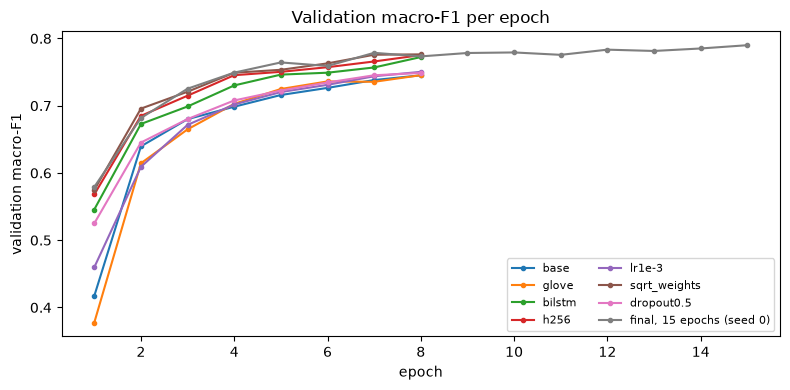

In [5]:
search = pd.read_csv(RESULTS / "search" / "lstm_search.csv")
fig, ax = plt.subplots(figsize=(8, 4))
curves = {name.removeprefix("lstm_"): RESULTS / "search" / name for name in search["run"]}
curves["final, 15 epochs (seed 0)"] = RESULTS / "lstm_seed0"
for label, run_dir in curves.items():
    history = pd.DataFrame(json.loads((run_dir / "log_history.json").read_text()))
    ax.plot(history["epoch"], history["val_macro_f1"], marker="o", ms=3, label=label)
ax.set(xlabel="epoch", ylabel="validation macro-F1", title="Validation macro-F1 per epoch")
ax.legend(fontsize=8, ncol=2)
fig.tight_layout()
if not cfg.fast_run:
    fig.savefig(FIGURES / "lstm_search_curves.png", dpi=150)
search[["step", "run", "val_macro_f1", "val_accuracy", "best_epoch", "trainable_params", "kept"]]

→ **Consequence:** reading the clause in both directions is the only change worth more than half a point (+2.7). GloVe
gives the same score with half the parameters, H = 256 and the √ class weights add 0.3 and 0.1 points, which is
within the noise of a single seed. A lower learning rate and more dropout lose 2.5 points, but at 8 epochs they
mostly slow learning down: every curve was still rising at its last epoch, so the final runs train for 15.

## 5. How stable is the result across seeds?

Seeds 0, 1 and 2 of the chosen configuration. Their test predictions are saved for the final evaluation and
are not read here.

In [6]:
rows = []
for seed in (0, 1, 2):
    run = runs.load_run(RESULTS / f"lstm_seed{seed}")
    m = run["metrics"]
    rows.append(
        {
            "seed": seed,
            "best_epoch": m["best_epoch"],
            "val_macro_f1": m["val"]["macro_f1"],
            "val_accuracy": m["val"]["accuracy"],
            "minutes": run["manifest"]["duration_s"] / 60,
        }
    )
finals = pd.DataFrame(rows)
mean, std = finals[["val_macro_f1", "val_accuracy"]].mean(), finals[["val_macro_f1", "val_accuracy"]].std()
print(
    f"validation macro-F1 {mean['val_macro_f1']:.4f} ± {std['val_macro_f1']:.4f}, accuracy "
    f"{mean['val_accuracy']:.4f} ± {std['val_accuracy']:.4f} (mean ± std over 3 seeds)"
)
finals.round(4)

validation macro-F1 0.7895 ± 0.0044, accuracy 0.8507 ± 0.0033 (mean ± std over 3 seeds)


,seed,best_epoch,val_macro_f1,val_accuracy,minutes
0,0,15,0.7900,0.8501,34.2483
1,1,15,0.7936,0.8543,28.6817
2,2,12,0.7848,0.8477,34.9483


→ **Consequence:** 0.790 ± 0.004 on validation. Training to 15 epochs added 1.4 points over the 8-epoch search run of
the same configuration; two seeds still peaked at their last epoch, so a few more epochs might add a little,
but not the 3.7 points that separate the LSTM from the TF-IDF baseline. The gap is real; the project architecture is now `notebooks/01` to `03`, plus `colab/run_m4.ipynb` and `scripts/train_bert.py` for the Transformer/LoRA extension.

## 6. Where does the BiLSTM fail, and where does it beat TF-IDF?

From the saved validation predictions of seed 0 and of the TF-IDF baseline (same clauses, same order): the
weakest types, the most confused pairs, scores by frequency band (tail: under 300 training clauses; head:
1 000 or more) and on clauses that do not appear word for word in the training set, then the types where
the two models differ most.

In [7]:
full = data.load_ledgar(
    replace(cfg, n_train_per_class=None, n_eval_per_class=None)
)  # the runs saw all clauses
full_counts = np.bincount(full["train"]["label"], minlength=cfg.n_classes)
lstm_val = runs.load_predictions(RESULTS / "lstm_seed0", "val")
tfidf_val = runs.load_predictions(RESULTS / "tfidf", "val")
y, pred = lstm_val["y_true"], lstm_val["y_pred"]
assert (tfidf_val["index"] == lstm_val["index"]).all() and len(y) == 10_000
saved = runs.load_run(RESULTS / "lstm_seed0")["metrics"]["val"]["macro_f1"]
assert np.isclose(metrics.macro_f1_score(y, pred, 100), saved), "the saved predictions give the saved score"
report = metrics.per_class_report(y, pred, LABELS, train_counts=full_counts)
report[report["support"] > 0].head(10).round(3)

,label,train_count,support,predicted,precision,recall,f1
1,Applicable Laws,352,69,31,0.387,0.174,0.240
2,Venues,131,19,24,0.375,0.474,0.419
3,Powers,125,15,13,0.462,0.400,0.429
4,Jurisdictions,202,33,44,0.409,0.545,0.468
5,Tax Withholdings,380,57,38,0.605,0.404,0.484
6,Assigns,31,3,1,1.000,0.333,0.500
7,Agreements,252,22,30,0.433,0.591,0.500
8,Indemnity,271,47,41,0.537,0.468,0.500
9,Qualifications,47,8,7,0.571,0.500,0.533
10,Enforceability,244,57,39,0.667,0.456,0.542


In [8]:
C = metrics.confusion(y, pred, cfg.n_classes)
pairs = metrics.most_confused(C, k=10, label_names=LABELS)
pairs

,class_a,class_b,label_a,label_b,a_as_b,b_as_a,total
0,4,47,Applicable Laws,Governing Laws,51,13,64
1,28,29,Defined Terms,Definitions,18,23,41
2,9,10,Authority,Authorizations,8,32,40
3,86,99,Tax Withholdings,Withholdings,26,9,35
4,49,50,Indemnifications,Indemnity,16,16,32
5,38,52,Entire Agreements,Integration,19,12,31
6,63,97,No Waivers,Waivers,16,15,31
7,76,98,Representations,Warranties,21,7,28
8,13,84,Binding Effects,Successors,14,13,27
9,87,99,Taxes,Withholdings,23,3,26


In [9]:
seen = data.seen_in_train(full, "validation")[lstm_val["index"]]
band = data.frequency_band(full_counts)
has_support = np.bincount(y, minlength=cfg.n_classes) > 0
slices = {}
for name, p in [("tf-idf", tfidf_val["y_pred"]), ("bilstm", pred)]:
    f1 = metrics.f1_scores(metrics.confusion(y, p, cfg.n_classes))[0]
    slices[name] = {
        "macro-F1": metrics.macro_f1_score(y, p, cfg.n_classes),
        **{f"{b} types": f1[(band == b) & has_support].mean() for b in ("head", "middle", "tail")},
        "clauses not in train": metrics.macro_f1_score(y[~seen], p[~seen], cfg.n_classes),
    }
pd.DataFrame(slices).T.round(4)

,macro-F1,head types,middle types,tail types,clauses not in train
tf-idf,0.8265,0.9243,0.8531,0.6733,0.8223
bilstm,0.7900,0.9172,0.8082,0.6394,0.7858


,label,support,tf-idf,bilstm,gain
50,Indemnity,47,0.667,0.500,-0.167
25,Costs,22,0.750,0.583,-0.167
23,Construction,69,0.740,0.587,-0.153
4,Applicable Laws,69,0.388,0.240,-0.148
1,Agreements,22,0.636,0.500,-0.136
78,Sanctions,24,0.735,0.776,0.041
5,Approvals,26,0.622,0.677,0.055
30,Disability,43,0.843,0.899,0.056
27,Death,51,0.887,0.961,0.074
72,Qualifications,8,0.400,0.533,0.133


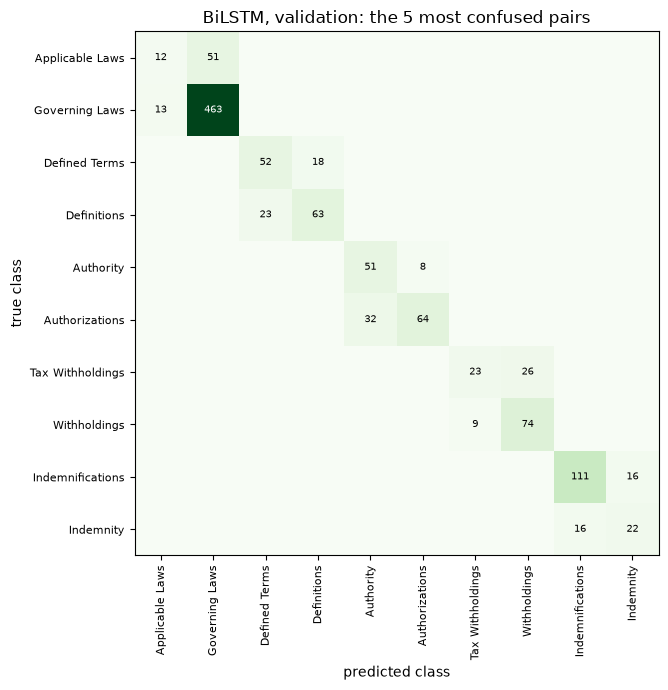

In [10]:
f1 = {
    name: metrics.f1_scores(metrics.confusion(y, p, cfg.n_classes))[0]
    for name, p in [("tf-idf", tfidf_val["y_pred"]), ("bilstm", pred)]
}
by_type = pd.DataFrame({"label": LABELS, "support": np.bincount(y, minlength=cfg.n_classes), **f1})
by_type = by_type[by_type["support"] > 0].assign(gain=lambda d: d["bilstm"] - d["tf-idf"]).sort_values("gain")
worst = list(dict.fromkeys(pairs[["class_a", "class_b"]].head(5).to_numpy().ravel()))
fig = plots.plot_confusion(
    C[np.ix_(worst, worst)],
    [LABELS[k] for k in worst],
    title="BiLSTM, validation: the 5 most confused pairs",
    path=None if cfg.fast_run else FIGURES / "lstm_confusion_pairs.png",
)
pd.concat([by_type.head(5), by_type.tail(5)]).round(3)

→ **Consequence:** a word-order model trained from scratch does not beat a bag of n-grams on this task. The clause type is
mostly signalled by a few key phrases (*governed by the laws*, *submits to the jurisdiction*), which TF-IDF
weighs directly, while the LSTM squeezes a clause of up to 476 words into one vector of 512 numbers and must
learn the language from 60 000 clauses only. It loses most on long, wordy types (*Indemnity*, *Construction*,
*Costs*) and on *Applicable Laws*, which it almost never recognises (recall 0.17); it gains on a few short,
formulaic types (*Death*, *Disability*). This is the case for a pretrained encoder: one that already knows
English and attends to every token instead of a single final state.

## Files used

`results/search/lstm_*` (search runs: configuration, metrics, per-epoch history), `results/search/lstm_search.csv`,
`results/lstm_seed{0,1,2}` (final runs, with weights and vocabulary for seed 0), `results/tfidf` (baseline).
Figures: `reports/figures/lstm_search_curves.png`, `reports/figures/lstm_confusion_pairs.png`.